In [141]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from tqdm import tqdm

import librosa
from scipy.io import wavfile

from sklearn.datasets import load_iris
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

SEED = 42
np.random.seed(SEED)

In [142]:
IRIS = False  # Flag to use iris instead of sound dataset
N_MFCC = 10
N_FFT = 1024
TARGET_SR = 16000
NEIGHBORS = 25  # Defines the range of neighbors to be tested in k-NN
LOWER_LIMIT = 3  # Defines the LOWER_LIMIT*10 number of neurons
UPPER_LIMIT = 20  # Defines the UPPER_LIMIT*10 number of neurons

# Module B

## Ex. 1

### Ex. 1.1.

#### Ex 1.1.1.

In [143]:
def train_test(X: np.ndarray, y: np.ndarray, test_size: float):
    ''' Takes in the features array, the labels array and a test size.
        Returns the splitted train and test data according to test size. '''
    X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=SEED, test_size=test_size, stratify=y)
    return X_train, X_test, y_train, y_test

#### Ex. 1.1.2.

In [144]:
def train_validation_test(X: np.ndarray, y: np.ndarray, val_size: float, test_size: float):
    ''' Takes in the features array, the labels array, a validation size and a test size.
        Returns the splitted train and test data according to valdation and test size. '''
    X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=SEED, test_size=test_size, stratify=y)
    X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=(val_size/(1-test_size)), stratify=y_train)
    return X_train, X_val, X_test, y_train, y_val, y_test

#### Ex 1.1.3.

In [145]:
def k_fold(X: np.ndarray, y: np.ndarray, n_splits: int):
    ''' Takes in the features array, the labels array and a number of splits/folds.
        Performs a stratified k-fold division over the dataset. 
        Returns a dict of folds, each being a dict with the train and validation features and train and validation labels. '''
    kf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    result = {}
    
    # Allocate dicts for folds
    for fold in range(n_splits):
        result[f"Fold {fold}"] = {}
    
    # Each fold is a dict with train and val data
    for i, (train_index, test_index) in enumerate(kf.split(X, y)):
        result[f"Fold {i}"]["X_train"] = X[train_index]
        result[f"Fold {i}"]["X_val"] = X[test_index]
        result[f"Fold {i}"]["y_train"] = y[train_index]
        result[f"Fold {i}"]["y_val"] = y[test_index]

    return result

#### Ex. 1.1.4. Advantages and Disadvantages

1. **Train-Test (TT)** - This strategy simply divides the dataset into 2 parts: training set (to train the model) and test set (to evaluate the model's performance). Here are some advantages and disadvantages:

    - Advantages: It's simple to implement and beneficial for very large datasets, whereas other methods would be too computationally intensive
    - Disadvantages: It runs the risk of not generalizing the model very well if one of the sets don't give a good representation of the dataset, thus incurring in underfitting or overfitting, and results can vary a lot based on how the data is splitted, which can be more prevalent in smaller datasets.

2. **Train-Validation-Test (TVT)** - Now there's a third set: the validation set (used to validate model's training/tuning). Let's see some advantages and disadvantages:

    - Advantages: The use of an independent dataset for model's validation/hyperparameter tuning aids in preventing overfitting and since the test set is kept separate from the other 2, we get an unbiased estimate of the model's performance.
    - Disadvantages: On top of previous issues with train-test, we also get a smaller training set, which can be problematic for smaller datasets.

3. **K-Fold Cross-Validation (K-Fold)** - This approach is different from the other 2, as now we get to divide the dataset into n separate train-test sets (folds), which can be used to perform cross-validation (train with n-1 folds and test with the other). Some advantages and disavantages include:

    - Advantages: We get a more reliable and robust performance of the model, the data is efficiently used, as every sample is used both for training and testing and there's less risk of overfitting since we average multiple runs with different train-test splits.
    - Disadvantages: This method requires the model to run multiple times, which can be very computationally intensive, something that is even more aggravating in deep learning models, where the training time is already substantial.

### Ex. 1.2.

In [146]:
def evaluation_metrics(y_true: np.ndarray, y_pred: np.ndarray):
    ''' Takes in the true labels and the predicted labels.
        Returns a confusion matrix, precision score, recall score and f1 score. '''
    conf_mat = confusion_matrix(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='micro')
    recall = recall_score(y_true, y_pred, average='micro')
    f1 = f1_score(y_true, y_pred, average='micro')
    return conf_mat, precision, recall, f1 

## Ex. 2

### Ex. 2.1.

In [147]:
# Code imported from module A to get a dictionary of file name lists aggregated by label
filenames = os.listdir('./dataset')
sample_filenames = {}

for label in filenames:
    if not label == '__MACOSX':
        sample_filenames[label] = os.listdir(f'./dataset/{label}')
        
labels = list(iter(sample_filenames.keys()))
for label in labels:
    print(f"{label}: {len(sample_filenames[label])}")

backward: 1664
forward: 1557
left: 3801
right: 3778
stop: 3872
_silence_: 408
_unknown_: 635


In [148]:
# Functions from module A to load audios and extract features

def load_normalized_audio(label: str, sample: str) -> tuple[int, np.ndarray]:
    ''' Takes in the class and the sample filename as arguments.
        Returns the sampling frequency and a normalized numpy array corresponding to the audio. '''
    fs, audio = wavfile.read(f'./dataset/{label}/{sample}')
    max_freq = np.iinfo(audio.dtype).max
    audio_norm = audio / max_freq
    return fs, audio_norm

def get_mfcc_features(sample_filenames: dict, label: str, n_mfcc: int = 16, n_fft: int = 1024, target_sr: int = 16000, 
                      aggregation: bool = True) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    ''' Takes in a dictionary with audio file names grouped by class, a class/label, the number of MFCC and FFT (Fast Fourier Transforms), 
        a target sample rate and an aggregation flag.
        The MFCC number will determine the number of features, FFT specifies the number of transformations of segments into the frequency spectrum, 
        target sample rate specifies the resample target rate to ensure all audios follow the same sample rate (the default in the dataset is 16000), aggregation specifies
        if each MFCC array will be aggregated (each MFCC is an array, not a value, thus we might need to process the array to reduce dimensionality).
        Returns 3 NumPy arrays corresponding to the MFCC, delta MFCC and delta-delta MFCC features the given class/label. '''
    mfcc_features = []
    dmfcc_features = []
    ddmfcc_features = []
    for filename in tqdm(sample_filenames[label]):
        sr, X = load_normalized_audio(label, filename)

        # Ensure all audios follow same sample rate (16000 in this case)
        X_res = librosa.resample(X, orig_sr=sr, target_sr=target_sr)

        # Zero padding for audios shorter than 1 second (less than 16000 samples)
        if len(X_res) < 16000:
            X_res = np.concatenate((X_res, np.zeros(16000-len(X_res))), axis=0)
        
        # MFCC feature extraction 
        X_mfcc = librosa.feature.mfcc(y=X_res, sr=target_sr, n_mfcc=n_mfcc, n_fft=n_fft)
        X_dmfcc = librosa.feature.delta(data=X_mfcc)
        X_ddmfcc = librosa.feature.delta(data=X_mfcc, order=2)

        # Extract mean and standard deviation from each MFCC (dimensionality reduction)
        if aggregation:
            X_mfcc_scaled = np.concat((np.mean(X_mfcc.T, axis=0), np.std(X_mfcc.T, axis=0)))
            X_dmfcc_scaled = np.concat((np.mean(X_dmfcc.T, axis=0), np.std(X_dmfcc.T, axis=0)))
            X_ddmfcc_scaled = np.concat((np.mean(X_ddmfcc.T, axis=0), np.std(X_ddmfcc.T, axis=0)))

        mfcc_features.append(X_mfcc_scaled)
        dmfcc_features.append(X_dmfcc_scaled)
        ddmfcc_features.append(X_ddmfcc_scaled)
    return (np.array(mfcc_features), np.array(dmfcc_features), np.array(ddmfcc_features))

def get_zcr_features(sample_filenames: dict, label: str, target_sr: int = 16000, aggregation: bool = True) -> np.ndarray:
    ''' Takes in a dictionary with audio file names grouped by class, a class/label, a target sample rate and an aggregation flag.
        Returns the computed Zero-crossing rate for all audios in a given class. '''
    zcr_features = []
    for filename in tqdm(sample_filenames[label]):
        sr, X = load_normalized_audio(label, filename)

        # Ensure all audios follow same sample rate (16000 in this case)
        X_res = librosa.resample(X, orig_sr=sr, target_sr=target_sr)

        # Zero padding for audios shorter than 1 second (less than 16000 samples)
        if len(X_res) < 16000:
            X_res = np.concatenate((X_res, np.zeros(16000-len(X_res))), axis=0)
        
        # Zero crossing rate feature extraction
        X_zcr = librosa.feature.zero_crossing_rate(y=X_res)

        zcr_features.append(np.array([np.mean(X_zcr), np.std(X_zcr)]))
    return np.array(zcr_features)

In [149]:
# Feature extraction from module A
X, y = None, None

if os.path.isfile(f"features{N_MFCC}.csv"):
    # Read features from a csv if the same N_MFCC was used
    df = pd.read_csv(f"features{N_MFCC}.csv")
    y = df['label'].to_numpy()
    X = df.drop(columns=['label']).to_numpy()
else:
    # Feature extraction process from module A
    all_class_features = {}  # Group all features into a single dictionary (separating by class)

    for label in labels:
        # Extract relevant features
        mfcc, dmfcc, ddmfcc = get_mfcc_features(sample_filenames, label, n_mfcc=N_MFCC)
        zcr = get_zcr_features(sample_filenames, label)
        
        # Aggregate all features on a dictionary, separating by label
        all_class_features[label] = []
        for i in range(len(mfcc)):
            all_class_features[label].append(np.concat((mfcc[i], dmfcc[i], ddmfcc[i], zcr[i])))
        all_class_features[label] = np.array(all_class_features[label])

    # Aggregate all label features on a single data and label arrays
    X = np.concat([samples for _, samples in all_class_features.items()])
    y = np.concat([[label]*len(samples) for label, samples in all_class_features.items()])

    # Transform newly computed features to a dataframe
    y_p = y.reshape((len(y), 1))
    data = np.concat([X, y_p], axis=1)
    feature_names = np.concat((np.array([f"MFCC Feature {i+1} Mean" for i in range(N_MFCC)]),
                               np.array([f"MFCC Feature {i+1} Stddev" for i in range(N_MFCC)]),
                               np.array([f"DMFCC Feature {i+1} Mean" for i in range(N_MFCC)]),
                               np.array([f"DMFCC Feature {i+1} Stddev" for i in range(N_MFCC)]),
                               np.array([f"DDMFCC Feature {i+1} Mean" for i in range(N_MFCC)]),
                               np.array([f"DDMFCC Feature {i+1} Stddev" for i in range(N_MFCC)]),
                               np.array(["ZCR Features Mean", "ZCR Features Std"]),
                               np.array(["label"])))

    # Save the dataframe
    df = pd.DataFrame(data=data, columns=feature_names)
    df.to_csv(f"features{N_MFCC}.csv", index=False)

print(f"Shapes: {X.shape, y.shape}")
X, y

Shapes: ((15715, 62), (15715,))


(array([[-3.47159378e+02,  1.37566628e+02,  2.30603902e-01, ...,
          5.67361698e-01,  1.42669678e-02,  2.68068003e-02],
        [-4.45815678e+02,  9.83320327e+01, -1.08899514e+01, ...,
          1.70633781e+00,  1.29913330e-01,  2.98610876e-02],
        [-4.93551740e+02,  1.13072836e+02, -1.80361292e+01, ...,
          1.87072597e+00,  1.35040283e-01,  3.94532567e-02],
        ...,
        [-4.24979889e+02,  1.29482806e+02,  2.31502488e+01, ...,
          1.43845239e+00,  6.26525879e-02,  2.41836162e-02],
        [-4.24077077e+02,  1.14769390e+02, -8.02667047e-01, ...,
          1.30987004e+00,  9.23461914e-02,  4.17867113e-02],
        [-4.34926351e+02,  4.64512079e+01,  7.68980484e+00, ...,
          1.48831096e+00,  1.31591797e-01,  1.16450408e-01]]),
 array(['backward', 'backward', 'backward', ..., '_unknown_', '_unknown_',
        '_unknown_'], dtype=object))

In [150]:
if IRIS:
    data = load_iris()
    X, y = data['data'], data.target
    print(f"Shapes: {X.shape, y.shape}")
    print(X[:3], y[:3])

#### Ex. 2.1.1.

In [151]:
# Perform a stratified train-validation-test split
X_train, X_val, X_test, y_train, y_val, y_test = train_validation_test(X, y, 0.3, 0.3)
X_train_toscale, X_val_toscale = np.copy(X_train), np.copy(X_val)
print(f"Train Shapes: {X_train.shape, y_train.shape}")
print(f"Validation Shapes: {X_val.shape, y_val.shape}")
print(f"Test Shapes: {X_test.shape, y_test.shape}")

Train Shapes: ((6285, 62), (6285,))
Validation Shapes: ((4715, 62), (4715,))
Test Shapes: ((4715, 62), (4715,))


#### Ex. 2.1.2.

In [152]:
# Perform a stratified k-fold cross validation split
X_train_folds, X_test_folds, y_train_folds, y_test_folds = train_test(X, y, 0.3)
folds = k_fold(X_train_folds, y_train_folds, n_splits=5)
shapes = (folds['Fold 0']['X_train'].shape, folds['Fold 0']['X_val'].shape, 
          folds['Fold 0']['y_train'].shape, folds['Fold 0']['y_val'].shape)
print(f"Folds: {len(folds)} | Shapes: {shapes}")
print(f"Test Shapes: {X_test_folds.shape, y_test_folds.shape}")

Folds: 5 | Shapes: ((8800, 62), (2200, 62), (8800,), (2200,))
Test Shapes: ((4715, 62), (4715,))


### Ex. 2.2.

In [153]:
# TVT - Normalize the splits
tvt_scaler = MinMaxScaler((0, 1))
X_train = tvt_scaler.fit_transform(X_train)
X_val, X_test = tvt_scaler.transform(X_val), tvt_scaler.transform(X_test)
X_train[:3], X_val[:3], X_test[:3]

(array([[0.27783824, 0.66293021, 0.87617962, 0.64823088, 0.81968359,
         0.7570014 , 0.84326449, 0.79004329, 0.82275317, 0.63506553,
         0.11728266, 0.0223868 , 0.06965181, 0.03043424, 0.05295071,
         0.0491208 , 0.05099441, 0.03020465, 0.05957445, 0.05375941,
         0.45426407, 0.4028131 , 0.52993616, 0.49777584, 0.58152157,
         0.57242363, 0.54063217, 0.46561448, 0.48422655, 0.47391597,
         0.09296804, 0.01604782, 0.06986706, 0.02756395, 0.04571793,
         0.03714439, 0.04033286, 0.00807212, 0.05452879, 0.07829198,
         0.7161468 , 0.45457037, 0.38198515, 0.49649665, 0.40731626,
         0.49083623, 0.42058029, 0.4173131 , 0.47232811, 0.50062362,
         0.10855146, 0.0159637 , 0.04689329, 0.03619092, 0.05699801,
         0.03475681, 0.04613429, 0.03238419, 0.03475787, 0.02199463,
         0.00263488, 0.00501654],
        [0.41529439, 0.45310957, 0.65803515, 0.54187786, 0.65243757,
         0.598604  , 0.66603026, 0.61841612, 0.47795425, 0.62433505,


In [154]:
# K-Folds - Normalize the splits
for fold in folds.keys():
    scaler = MinMaxScaler((0, 1))
    folds[fold]['X_train'] = scaler.fit_transform(folds[fold]['X_train'])
    folds[fold]['X_val'] = scaler.transform(folds[fold]['X_val'])
    folds[fold]['X_test'] = scaler.transform(X_test_folds)

folds['Fold 0']['X_train'][:3], folds['Fold 0']['X_val'][:3], folds['Fold 0']['X_train'][:3]

(array([[0.46588051, 0.2895714 , 0.34965379, 0.59703037, 0.2960535 ,
         0.68720269, 0.4251834 , 0.6202735 , 0.40630559, 0.21983388,
         0.48016521, 0.24142373, 0.3447188 , 0.11586208, 0.30127206,
         0.32521422, 0.28107757, 0.38486725, 0.48740264, 0.33920335,
         0.520812  , 0.49541327, 0.52895536, 0.45039879, 0.6550813 ,
         0.53056133, 0.51879506, 0.51115179, 0.43514707, 0.37647813,
         0.53811385, 0.25025394, 0.33951405, 0.10351305, 0.28291898,
         0.26514521, 0.31727131, 0.39485018, 0.66636767, 0.36648839,
         0.62015985, 0.5706551 , 0.55236961, 0.41822846, 0.40303896,
         0.47849957, 0.5153635 , 0.38330143, 0.30479632, 0.3935328 ,
         0.35704571, 0.26570983, 0.30591456, 0.09427961, 0.27855064,
         0.37778312, 0.18668656, 0.44850977, 0.57092959, 0.56666363,
         0.51425571, 0.33999377],
        [0.37974047, 0.61290985, 0.56487278, 0.41227682, 0.63014086,
         0.63704703, 0.64560374, 0.33480108, 0.4258784 , 0.30303772,


### Ex. 2.3.

In [155]:
def PCA(X: np.ndarray, threshold: float) -> tuple[np.int64, np.ndarray, np.ndarray]:
    ''' Takes in an array with feature arrays and a cumulative explained variance threshold. 
        Computes the PCA algorithm.
        Returns the number of principal components for the given threshold, along with the feature indices and cumulative explained variance of all features. '''
    # Step 1: Standardize each feature (Z = (X-mean(X))/std(X))
    X_scaled = np.zeros(X.shape)
    for i in range(len(X.T)):
        X_scaled[:, i] = (X.T[i] - np.mean(X.T[i])) / np.std(X.T[i])

    # Step 2: Compute the covariance matrix (for combination(x1, x2) in features: cov(x1, x2))
    X_scaled_cov = np.cov(X_scaled.T)

    # Step 3: Compute eigenvalues and eigenvectors of covariance matrix (cov_mat*X = k*X)
    # Note: Eigenvalues represent the magnitude of variance, eigenvectors represent the principle components (directions)
    # Note 2: The eigenvalue eigval[i] corresponds to the eigenvector eigvec[:, i] and vice-versa
    eigval, eigvec = np.linalg.eig(X_scaled_cov)

    # Step 4: Sort eigenvalues and eigenvectors from highest to lowest (variance)
    idx = eigval.argsort()[::-1]  # Indices of eigenvalues in descending order
    eigval = eigval[idx]
    eigvec = eigvec[:, idx]

    # Step 5: Compute the explained variance (eigval[i] / sum(eigval) -> ratio of variance of eigval[i])
    exp_var = eigval / np.sum(eigval)

    # Step 6: Compute the cumulative explained variance (cum_exp_var[i] = sum(exp_var[:i]) -> total var of first k features)
    cum_exp_var = np.cumsum(exp_var)

    # Step 7: Compute the number of principal components exceeding threshold (cum_exp_var >= threshold)
    # Note: First index of true + 1 indicates number of components within 
    n_comp = np.argmax(cum_exp_var >= threshold) + 1

    return n_comp, idx, cum_exp_var

In [156]:
# TVT - Computing the rankings according to PCA
n_comp, pca_ranks_tvt, pca_score_tvt = PCA(X_train, 0.75)
print(f"PCA Ranking:\n {pca_ranks_tvt} \nPCA Cumulative Explained Variance:\n {pca_score_tvt}")

PCA Ranking:
 [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 50 51 52 53 54 55 57 61
 60 59 58 56 49 48 47 46 45 44 43 42 41 40] 
PCA Cumulative Explained Variance:
 [0.18967187 0.24728596 0.28947306 0.32962049 0.36637488 0.40193165
 0.4350866  0.46578563 0.49555057 0.52349448 0.54913897 0.57401938
 0.59810822 0.62101479 0.64195055 0.66257899 0.68127735 0.69959698
 0.71723926 0.73401709 0.75037011 0.76483562 0.77881651 0.79262768
 0.80606827 0.81849027 0.83062218 0.84217636 0.85348979 0.86445911
 0.87487875 0.88504511 0.89453998 0.90385164 0.91246712 0.92091731
 0.92849086 0.93533008 0.94184328 0.94671974 0.95099941 0.95511146
 0.95909829 0.96303435 0.96675211 0.97031894 0.97356526 0.97662691
 0.97961921 0.98254681 0.98534266 0.98792892 0.99003984 0.99154725
 0.9929582  0.99426307 0.99546163 0.99662675 0.99765199 0.99853215
 0.99937745 1.        ]


In [157]:
# K-Fold - Computing the rankings according to PCA
pca_folds = {}

for fold in folds.keys():
    n_comp, idx, cum_exp_var = PCA(folds[fold]["X_train"], 0.75)
    pca_folds[fold] = (cum_exp_var, idx)

    print(fold)
    print(f"PCA Ranking:\n {idx} \nPCA Cumulative Explained Variance:\n {cum_exp_var}\n")

Fold 0
PCA Ranking:
 [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 50 51 52 54 55 56 57 59
 60 61 58 53 49 48 47 46 45 44 43 42 41 40] 
PCA Cumulative Explained Variance:
 [0.19020961 0.24793847 0.28980179 0.32921362 0.36663492 0.40194963
 0.43521488 0.46575295 0.49540102 0.52327157 0.5489763  0.57400231
 0.59809982 0.62121444 0.64224159 0.66304134 0.68187349 0.70010842
 0.71776349 0.73486798 0.75079121 0.76545109 0.77953389 0.79333718
 0.80684636 0.81923457 0.8313385  0.84265662 0.85374793 0.86458907
 0.87481028 0.88488741 0.89461664 0.90378505 0.91232878 0.92067621
 0.92832427 0.93536082 0.94206817 0.94691766 0.95122681 0.95531579
 0.95930132 0.96312943 0.96683689 0.97033947 0.97368467 0.97670401
 0.97968195 0.98256381 0.98539875 0.98800441 0.99011735 0.99157985
 0.99299829 0.99430976 0.9954998  0.996647   0.99764259 0.99852608
 0.9993651  1.        ]

Fold 1
PCA Ranking:
 [ 0  1  2  3  4  5  6  7  8  9 10 11

#### Ex. 2.3.1.

In [158]:
# TVT - Get feature subsets according to PCA's ranking
tvt_subsets = {}
for i in range(len(pca_ranks_tvt)):
    tvt_subsets[f"Features {i+1}"] = X_train.T[pca_ranks_tvt[:i+1]].T
tvt_subsets

{'Features 1': array([[0.27783824],
        [0.41529439],
        [0.44785398],
        ...,
        [0.44763823],
        [0.38405371],
        [0.30308197]]),
 'Features 2': array([[0.27783824, 0.66293021],
        [0.41529439, 0.45310957],
        [0.44785398, 0.45358319],
        ...,
        [0.44763823, 0.61417017],
        [0.38405371, 0.43820038],
        [0.30308197, 0.36351614]]),
 'Features 3': array([[0.27783824, 0.66293021, 0.87617962],
        [0.41529439, 0.45310957, 0.65803515],
        [0.44785398, 0.45358319, 0.40725255],
        ...,
        [0.44763823, 0.61417017, 0.51957061],
        [0.38405371, 0.43820038, 0.65007769],
        [0.30308197, 0.36351614, 0.79421336]]),
 'Features 4': array([[0.27783824, 0.66293021, 0.87617962, 0.64823088],
        [0.41529439, 0.45310957, 0.65803515, 0.54187786],
        [0.44785398, 0.45358319, 0.40725255, 0.63810436],
        ...,
        [0.44763823, 0.61417017, 0.51957061, 0.49283367],
        [0.38405371, 0.43820038, 0.6500776

In [159]:
# K-Folds - Get feature subsets according to PCA's ranking
folds_subsets = {}
for fold in folds:
    folds_subsets[fold] = {}
    f_scores, f_ranks = pca_folds[fold]
    for i in range(len(f_ranks)):
        folds_subsets[fold][f"Features {i+1}"] = folds[fold]["X_train"].T[f_ranks[:i+1]].T
folds_subsets

{'Fold 0': {'Features 1': array([[0.46588051],
         [0.37974047],
         [0.43582094],
         ...,
         [0.40013651],
         [0.43513119],
         [0.42435751]]),
  'Features 2': array([[0.46588051, 0.2895714 ],
         [0.37974047, 0.61290985],
         [0.43582094, 0.58576189],
         ...,
         [0.40013651, 0.64658009],
         [0.43513119, 0.58147239],
         [0.42435751, 0.70711187]]),
  'Features 3': array([[0.46588051, 0.2895714 , 0.34965379],
         [0.37974047, 0.61290985, 0.56487278],
         [0.43582094, 0.58576189, 0.62765235],
         ...,
         [0.40013651, 0.64658009, 0.78682799],
         [0.43513119, 0.58147239, 0.67685948],
         [0.42435751, 0.70711187, 0.57984206]]),
  'Features 4': array([[0.46588051, 0.2895714 , 0.34965379, 0.59703037],
         [0.37974047, 0.61290985, 0.56487278, 0.41227682],
         [0.43582094, 0.58576189, 0.62765235, 0.57602428],
         ...,
         [0.40013651, 0.64658009, 0.78682799, 0.56962188],
      

### Ex. 2.4.

In [160]:
# k-NN classifiers with k = [1, NEIGHBORS] (which will be trained n_feature times, separately)
# Note: Only a NEIGHBORS amount of knn_models created to lower memory consumption
knn_models = []
for k in range(NEIGHBORS):
    knn_models.append(KNeighborsClassifier(n_neighbors=k+1))
knn_models[0]

KNeighborsClassifier(n_neighbors=1)

### Ex. 2.5.

In [161]:
def validation_stats(models: list, X_val: np.ndarray, y_val: np.ndarray) -> np.ndarray:
    ''' Takes in a list of models, validation features and labels.
        Returns an array of F1-Scores for all the models, using the provided validation data. '''
    scores = []
    for model in models:
        preds = model.predict(X_val)
        f1 = f1_score(y_val, preds, average='micro')  # Custom function defined previously
        scores.append(f1)
    return np.array(scores)

def plot_knn_stats(scores: np.ndarray[np.ndarray]) -> None:
    ''' Takes in the list of evaluation scores for each feature subset and k values. 
        Plots all feature subset perfomances according to their score and k value. '''
    neighbors = [i for i in range(1, NEIGHBORS+1)]
    plt.figure(figsize=(10, 6))
    for i in range(len(scores)):
        plt.plot(neighbors, scores[i], label=f"Features {i+1}")
    plt.xlabel("Neighbors")
    plt.ylabel("F1 Score")
    plt.title("Model Performances")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

#### Ex. 2.5.1.

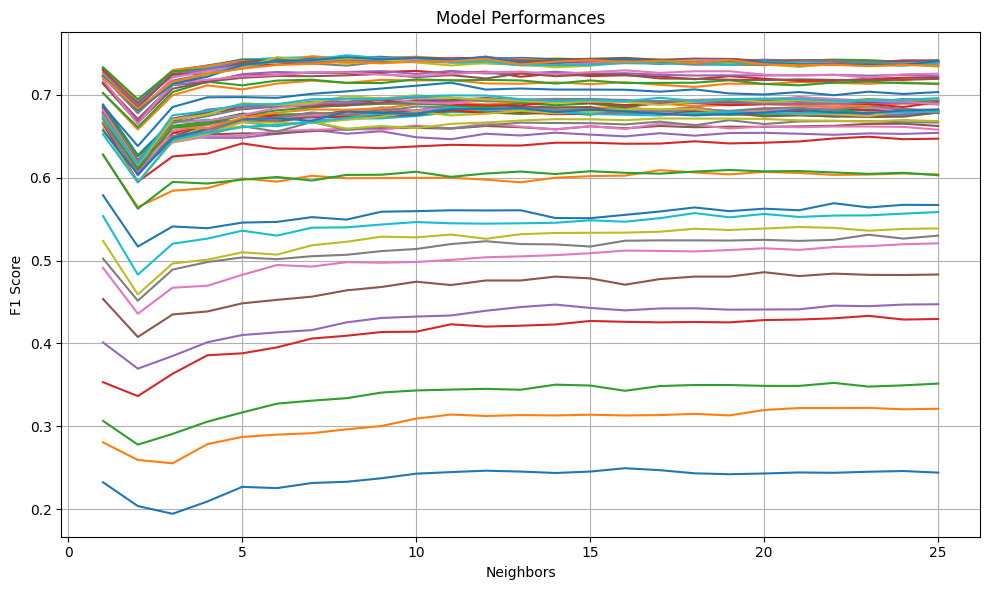

Features 1: Best neighbor number = 16 | F1 score = 0.250
Features 2: Best neighbor number = 23 | F1 score = 0.322
Features 3: Best neighbor number = 22 | F1 score = 0.352
Features 4: Best neighbor number = 23 | F1 score = 0.433
Features 5: Best neighbor number = 25 | F1 score = 0.447
Features 6: Best neighbor number = 20 | F1 score = 0.486
Features 7: Best neighbor number = 25 | F1 score = 0.521
Features 8: Best neighbor number = 23 | F1 score = 0.531
Features 9: Best neighbor number = 21 | F1 score = 0.540
Features 10: Best neighbor number = 25 | F1 score = 0.558
Features 11: Best neighbor number = 1 | F1 score = 0.579
Features 12: Best neighbor number = 1 | F1 score = 0.627
Features 13: Best neighbor number = 1 | F1 score = 0.628
Features 14: Best neighbor number = 1 | F1 score = 0.664
Features 15: Best neighbor number = 1 | F1 score = 0.670
Features 16: Best neighbor number = 1 | F1 score = 0.676
Features 17: Best neighbor number = 1 | F1 score = 0.676
Features 18: Best neighbor num

In [162]:
# TVT - Train each model and plot the F1-scores for all combinations of different k and feature numbers
tvt_scores = []

if os.path.isfile(f"scores{N_MFCC}_tvt.csv"):
    # Read the scores from a csv if the same N_MFCC was used
    df = pd.read_csv(f"scores{N_MFCC}_tvt.csv")
    tvt_scores = df.to_numpy()
else:
    for features in tqdm(tvt_subsets.keys()):
        for model in knn_models:
            model.fit(tvt_subsets[features], y_train)
        n_features = int(features[9-len(features):])  # Get number of features of current models
        tvt_scores.append(validation_stats(knn_models, 
                                           X_val.T[pca_ranks_tvt[:n_features]].T, 
                                           y_val))
    tvt_scores = np.array(tvt_scores)
    
    # Save f1 scores to a csv file
    df = pd.DataFrame(data=tvt_scores)
    df.to_csv(f"scores{N_MFCC}_tvt.csv", index=False)
    
plot_knn_stats(tvt_scores)
for n_features in range(len(tvt_scores)):
    print(f"Features {n_features+1}: Best neighbor number = {np.argmax(tvt_scores[n_features])+1} | F1 score = {np.max(tvt_scores[n_features]):.3f}")

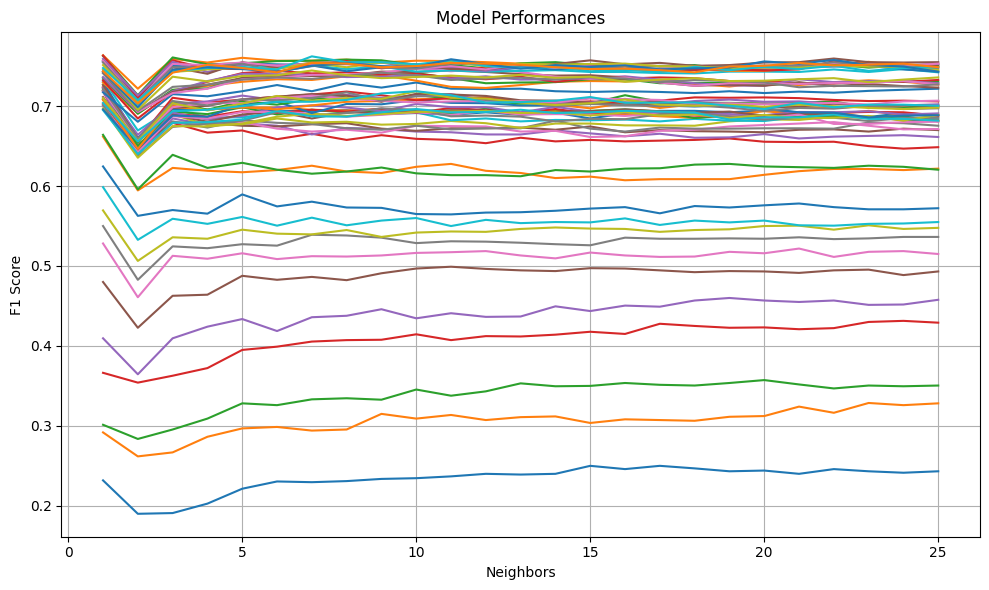

Features 1: Best neighbor number = 15 | F1 score = 0.250
Features 2: Best neighbor number = 23 | F1 score = 0.329
Features 3: Best neighbor number = 20 | F1 score = 0.357
Features 4: Best neighbor number = 24 | F1 score = 0.431
Features 5: Best neighbor number = 19 | F1 score = 0.460
Features 6: Best neighbor number = 11 | F1 score = 0.499
Features 7: Best neighbor number = 1 | F1 score = 0.528
Features 8: Best neighbor number = 1 | F1 score = 0.550
Features 9: Best neighbor number = 1 | F1 score = 0.570
Features 10: Best neighbor number = 1 | F1 score = 0.599
Features 11: Best neighbor number = 1 | F1 score = 0.625
Features 12: Best neighbor number = 1 | F1 score = 0.662
Features 13: Best neighbor number = 1 | F1 score = 0.664
Features 14: Best neighbor number = 1 | F1 score = 0.703
Features 15: Best neighbor number = 1 | F1 score = 0.700
Features 16: Best neighbor number = 1 | F1 score = 0.711
Features 17: Best neighbor number = 1 | F1 score = 0.710
Features 18: Best neighbor number 

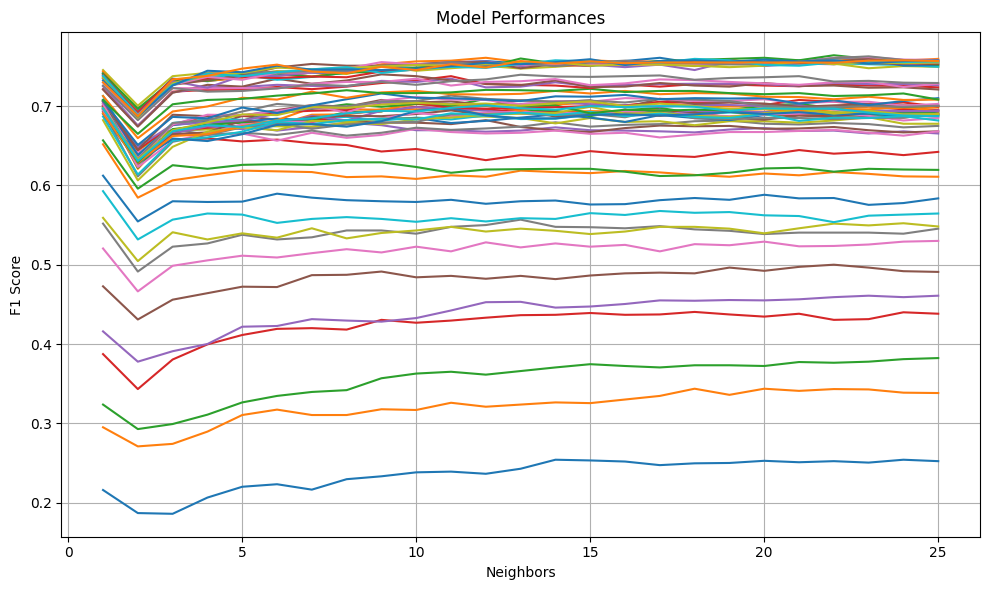

Features 1: Best neighbor number = 14 | F1 score = 0.254
Features 2: Best neighbor number = 18 | F1 score = 0.344
Features 3: Best neighbor number = 25 | F1 score = 0.382
Features 4: Best neighbor number = 18 | F1 score = 0.440
Features 5: Best neighbor number = 23 | F1 score = 0.461
Features 6: Best neighbor number = 22 | F1 score = 0.500
Features 7: Best neighbor number = 25 | F1 score = 0.530
Features 8: Best neighbor number = 13 | F1 score = 0.557
Features 9: Best neighbor number = 1 | F1 score = 0.559
Features 10: Best neighbor number = 1 | F1 score = 0.593
Features 11: Best neighbor number = 1 | F1 score = 0.612
Features 12: Best neighbor number = 1 | F1 score = 0.652
Features 13: Best neighbor number = 1 | F1 score = 0.657
Features 14: Best neighbor number = 1 | F1 score = 0.693
Features 15: Best neighbor number = 1 | F1 score = 0.700
Features 16: Best neighbor number = 1 | F1 score = 0.696
Features 17: Best neighbor number = 1 | F1 score = 0.695
Features 18: Best neighbor numbe

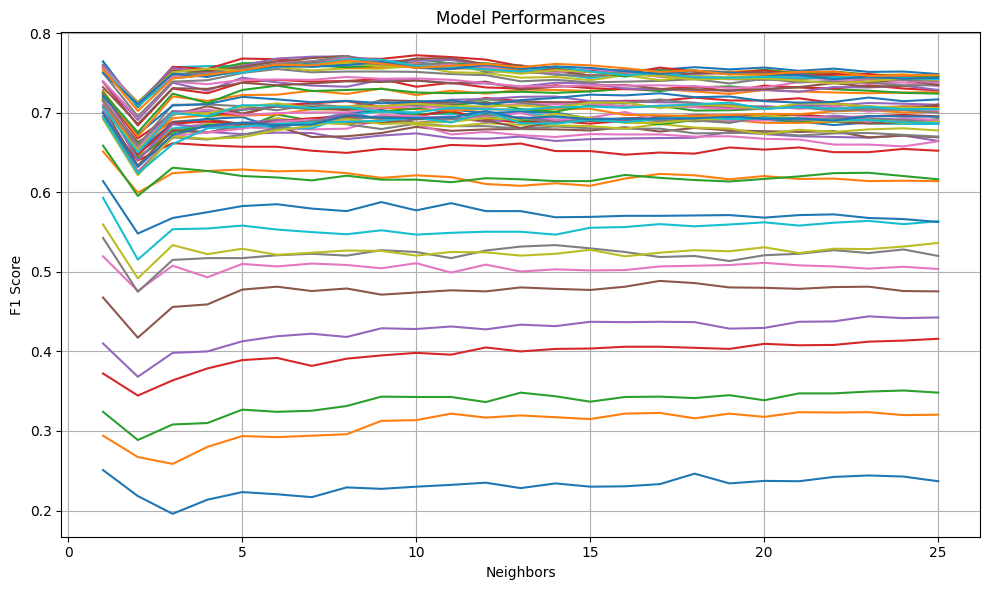

Features 1: Best neighbor number = 1 | F1 score = 0.251
Features 2: Best neighbor number = 21 | F1 score = 0.324
Features 3: Best neighbor number = 24 | F1 score = 0.351
Features 4: Best neighbor number = 25 | F1 score = 0.416
Features 5: Best neighbor number = 23 | F1 score = 0.444
Features 6: Best neighbor number = 17 | F1 score = 0.489
Features 7: Best neighbor number = 1 | F1 score = 0.520
Features 8: Best neighbor number = 1 | F1 score = 0.543
Features 9: Best neighbor number = 1 | F1 score = 0.560
Features 10: Best neighbor number = 1 | F1 score = 0.593
Features 11: Best neighbor number = 1 | F1 score = 0.614
Features 12: Best neighbor number = 1 | F1 score = 0.651
Features 13: Best neighbor number = 1 | F1 score = 0.659
Features 14: Best neighbor number = 1 | F1 score = 0.695
Features 15: Best neighbor number = 1 | F1 score = 0.710
Features 16: Best neighbor number = 1 | F1 score = 0.716
Features 17: Best neighbor number = 1 | F1 score = 0.715
Features 18: Best neighbor number =

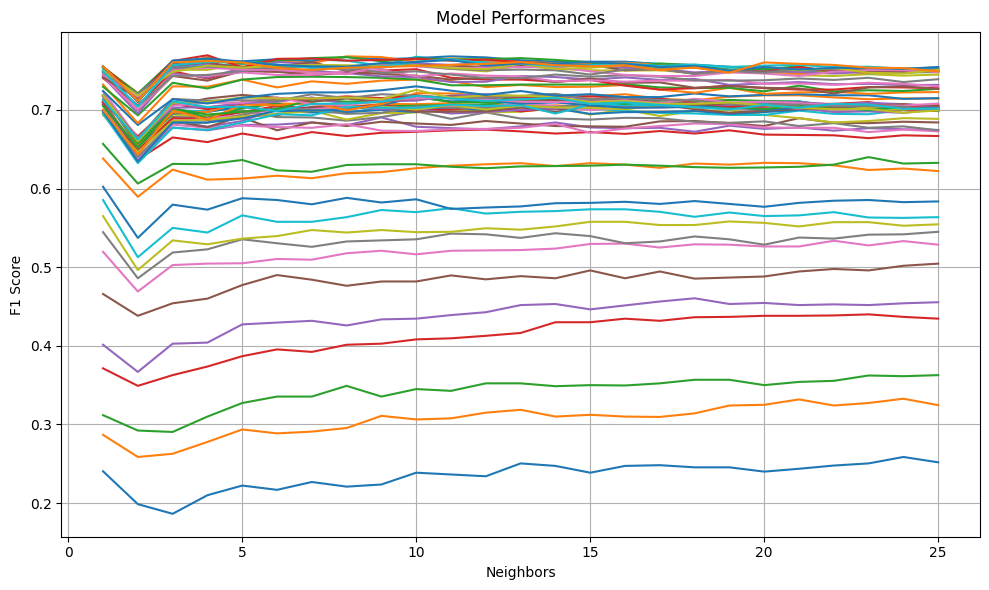

Features 1: Best neighbor number = 24 | F1 score = 0.259
Features 2: Best neighbor number = 24 | F1 score = 0.333
Features 3: Best neighbor number = 25 | F1 score = 0.363
Features 4: Best neighbor number = 23 | F1 score = 0.440
Features 5: Best neighbor number = 18 | F1 score = 0.460
Features 6: Best neighbor number = 25 | F1 score = 0.505
Features 7: Best neighbor number = 22 | F1 score = 0.534
Features 8: Best neighbor number = 25 | F1 score = 0.545
Features 9: Best neighbor number = 1 | F1 score = 0.565
Features 10: Best neighbor number = 1 | F1 score = 0.585
Features 11: Best neighbor number = 1 | F1 score = 0.602
Features 12: Best neighbor number = 1 | F1 score = 0.638
Features 13: Best neighbor number = 1 | F1 score = 0.657
Features 14: Best neighbor number = 1 | F1 score = 0.697
Features 15: Best neighbor number = 1 | F1 score = 0.706
Features 16: Best neighbor number = 1 | F1 score = 0.713
Features 17: Best neighbor number = 1 | F1 score = 0.709
Features 18: Best neighbor numbe

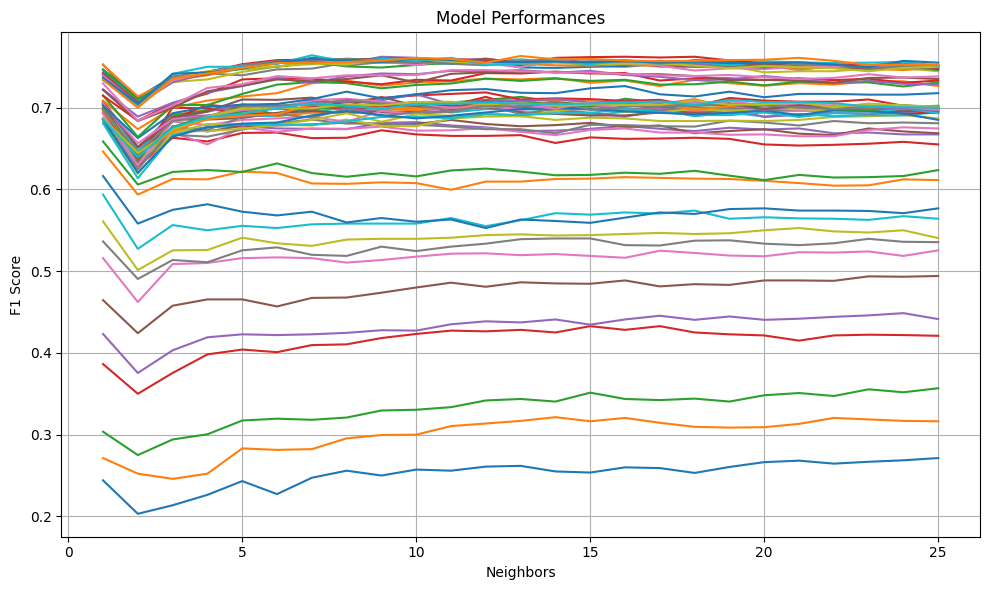

Features 1: Best neighbor number = 25 | F1 score = 0.271
Features 2: Best neighbor number = 14 | F1 score = 0.321
Features 3: Best neighbor number = 25 | F1 score = 0.357
Features 4: Best neighbor number = 15 | F1 score = 0.433
Features 5: Best neighbor number = 24 | F1 score = 0.449
Features 6: Best neighbor number = 25 | F1 score = 0.494
Features 7: Best neighbor number = 25 | F1 score = 0.525
Features 8: Best neighbor number = 14 | F1 score = 0.540
Features 9: Best neighbor number = 1 | F1 score = 0.561
Features 10: Best neighbor number = 1 | F1 score = 0.594
Features 11: Best neighbor number = 1 | F1 score = 0.616
Features 12: Best neighbor number = 1 | F1 score = 0.646
Features 13: Best neighbor number = 1 | F1 score = 0.659
Features 14: Best neighbor number = 1 | F1 score = 0.693
Features 15: Best neighbor number = 1 | F1 score = 0.698
Features 16: Best neighbor number = 1 | F1 score = 0.696
Features 17: Best neighbor number = 1 | F1 score = 0.686
Features 18: Best neighbor numbe

In [163]:
# K-Folds - Train each model and plot the F1-scores for all combinations of different k and feature numbers
fold_scores = []

for fold in folds.keys():
    scores = []
    
    if os.path.isfile(f"scores{N_MFCC}_fold{fold[-1]}.csv"):
        # Read the scores from a csv if the same N_MFCC was used
        df = pd.read_csv(f"scores{N_MFCC}_fold{fold[-1]}.csv")
        scores = df.to_numpy()
    else:
        _, pca_ranks = pca_folds[fold]
        for features in tqdm(folds_subsets[fold].keys()):
            for model in knn_models:
                model.fit(folds_subsets[fold][features], folds[fold]["y_train"])
            n_features = int(features[9-len(features):])  # Get number of features of current models
            scores.append(validation_stats(knn_models, 
                                           folds[fold]["X_val"].T[pca_ranks[:n_features]].T, 
                                           folds[fold]["y_val"]))
        scores = np.array(scores)
        
        # Save f1 scores to a csv file
        df = pd.DataFrame(data=scores)
        df.to_csv(f"scores{N_MFCC}_fold{fold[-1]}.csv", index=False)
    
    fold_scores.append(scores)
    plot_knn_stats(scores)
    for n_features in range(len(scores)):
        print(f"Features {n_features+1}: Best neighbor number = {np.argmax(scores[n_features])+1} | F1 score = {np.max(scores[n_features]):.3f}")
        
fold_scores = np.array(fold_scores)

#### Ex. 2.5.2.

In [164]:
# Best feature combination and best neighbor number for that feature combination
all_scores = np.append(fold_scores, np.expand_dims(tvt_scores, axis=0), axis=0)  # Shape: (6, n_feat, neigh)
avg_all_scores = np.mean(all_scores, axis=0)  # Average the scores (Shape: (n_feat, neigh))
best_comb = np.argmax(avg_all_scores)  # Absolute position of best average score
best_feat, best_neigh = best_comb//NEIGHBORS+1, best_comb%NEIGHBORS+1

print(f"Best feature number: {best_feat} | Best neighbor number: {best_neigh} | Average F1 score: {avg_all_scores[best_feat-1, best_neigh-1]:.3f}")

Best feature number: 52 | Best neighbor number: 10 | Average F1 score: 0.757


### Ex. 2.6.

In [165]:
# TVT - Different parameters for the best feature combination and neighbor number
weights = ["uniform", "distance"]
p_vals = [1, 2, 3]
models =  []
params = []

for weight in weights:
    for p in p_vals:
        model = KNeighborsClassifier(n_neighbors=best_neigh, weights=weight, p=p)
        model.fit(tvt_subsets[f"Features {best_feat}"], y_train)
        models.append(model)
        params.append((p, weight))
        
tvt_scores = validation_stats(models, X_val.T[pca_ranks_tvt[:best_feat]].T, y_val)
for i in range(len(tvt_scores)):
    p, weight = params[i]
    print(f"p={p} weight={weight}: F1 score={tvt_scores[i]:.3f}")

p=1 weight=uniform: F1 score=0.739
p=2 weight=uniform: F1 score=0.746
p=3 weight=uniform: F1 score=0.733
p=1 weight=distance: F1 score=0.752
p=2 weight=distance: F1 score=0.754
p=3 weight=distance: F1 score=0.745


In [166]:
# K-Fold - Different parameters for the best feature combination and neighbor number
weights = ["uniform", "distance"]
p_vals = [1, 2, 3]
folds_scores = []

for fold in folds_subsets.keys():
    print(fold)
    models =  []
    for weight in weights:
        for p in p_vals:
            model = KNeighborsClassifier(n_neighbors=best_neigh, weights=weight, p=p)
            model.fit(folds_subsets[fold][f"Features {best_feat}"], folds[fold]["y_train"])
            models.append(model)
                
    fold_scores = validation_stats(models, 
                                   folds[fold]["X_val"].T[pca_folds[fold][1][:best_feat]].T, 
                                   folds[fold]["y_val"])
    folds_scores.append(fold_scores)
    for i in range(len(fold_scores)):
        p, weight = params[i]
        print(f"p={p} weight={weight}: F1 score={fold_scores[i]:.3f}")
    print()

Fold 0
p=1 weight=uniform: F1 score=0.746
p=2 weight=uniform: F1 score=0.757
p=3 weight=uniform: F1 score=0.753
p=1 weight=distance: F1 score=0.765
p=2 weight=distance: F1 score=0.767
p=3 weight=distance: F1 score=0.765

Fold 1
p=1 weight=uniform: F1 score=0.759
p=2 weight=uniform: F1 score=0.756
p=3 weight=uniform: F1 score=0.740
p=1 weight=distance: F1 score=0.769
p=2 weight=distance: F1 score=0.765
p=3 weight=distance: F1 score=0.757

Fold 2
p=1 weight=uniform: F1 score=0.767
p=2 weight=uniform: F1 score=0.763
p=3 weight=uniform: F1 score=0.751
p=1 weight=distance: F1 score=0.775
p=2 weight=distance: F1 score=0.775
p=3 weight=distance: F1 score=0.765

Fold 3
p=1 weight=uniform: F1 score=0.757
p=2 weight=uniform: F1 score=0.761
p=3 weight=uniform: F1 score=0.762
p=1 weight=distance: F1 score=0.764
p=2 weight=distance: F1 score=0.775
p=3 weight=distance: F1 score=0.767

Fold 4
p=1 weight=uniform: F1 score=0.756
p=2 weight=uniform: F1 score=0.758
p=3 weight=uniform: F1 score=0.751
p=1 

### Ex. 2.7.

In [167]:
# Training data = training + validation data
X_train_val = np.concat((X_train, X_val)).T[pca_ranks_tvt[:best_feat]].T
y_train_val = np.concat((y_train, y_val))

# Re-normalize data to fit the new scaling
scaler_combined = MinMaxScaler()
scaler_combined.fit(X_train_val)
X_train_val_scaled = scaler_combined.transform(X_train_val)
X_test_scaled = scaler_combined.transform(X_test.T[pca_ranks_tvt[:best_feat]].T)

X_train_val.shape, y_train_val.shape

((11000, 52), (11000,))

#### Ex. 2.7.1.

In [168]:
# Get best parameter combination
all_scores = np.concat(([tvt_scores], folds_scores))  # Aggregate all validation split scores
avg_all_scores = np.mean(all_scores, axis=0)
best_comb = np.argmax(avg_all_scores)  # Get the best mean scores across all splits
best_p, best_weight = params[best_comb]

print(f"Best feature number: {best_feat} | Best neighbor number: {best_neigh} | Best power metric: {best_p}\
 | Best weight function: {best_weight} | Average F1 score: {avg_all_scores[best_comb]:.3f}")

Best feature number: 52 | Best neighbor number: 10 | Best power metric: 2 | Best weight function: distance | Average F1 score: 0.766


#### Ex. 2.7.2.

Precision score: 0.777
Recall score: 0.777
F1 score: 0.777


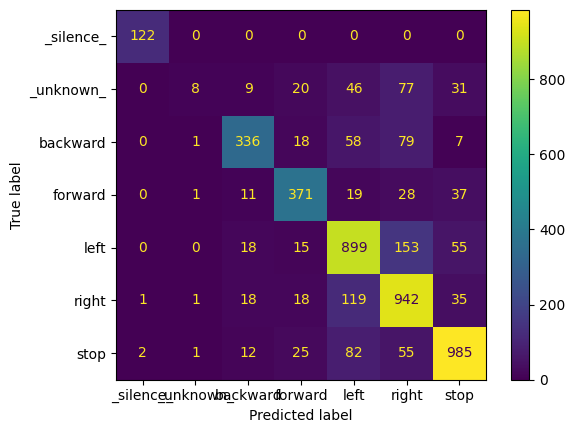

In [169]:
# Classification with the best model on test set
model = KNeighborsClassifier(n_neighbors=best_neigh, p=best_p, weights=best_weight)
model.fit(X_train_val_scaled, y_train_val)
preds = model.predict(X_test_scaled)
confmat, precision, recall, f1 = evaluation_metrics(y_test, preds)

print(f"Precision score: {precision:.3f}\nRecall score: {recall:.3f}\nF1 score: {f1:.3f}")
ConfusionMatrixDisplay.from_predictions(y_test, preds);

#### Ex. 2.7.3.

Precision score: 1.000
Recall score: 1.000
F1 score: 1.000


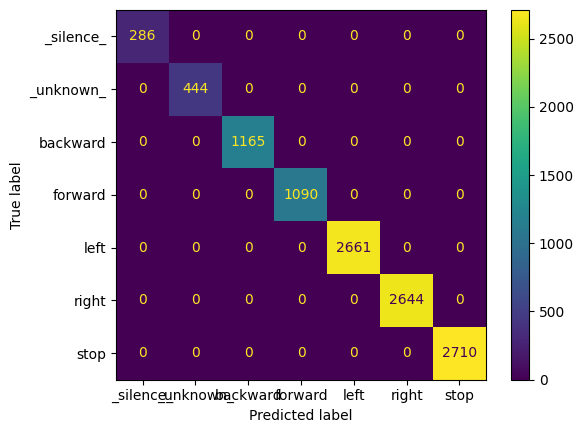

In [172]:
# Classification with the best model on training set
model = KNeighborsClassifier(n_neighbors=best_neigh, p=best_p, weights=best_weight)
model.fit(X_train_val_scaled, y_train_val)
preds = model.predict(X_train_val_scaled)
confmat, precision, recall, f1 = evaluation_metrics(y_train_val, preds)

print(f"Precision score: {precision:.3f}\nRecall score: {recall:.3f}\nF1 score: {f1:.3f}")
ConfusionMatrixDisplay.from_predictions(y_train_val, preds);

#### Ex. 2.7.4. Overfitting assessment

Given that the models average at a 100% precision, recall and f1 scores for all training sets, we can already tell that the models are fitting them perfectly and, thus, overfitting. Also, the test sets results are, on average, 25-30% lower for all the metrics, reinforcing the fact that the model is definitely overfitting to the training data.

## Ex. 3

### Ex. 3.1.

#### Ex. 3.1.1.

In [117]:
import warnings
from sklearn.exceptions import ConvergenceWarning

# Suppress ConvergenceWarnings
warnings.filterwarnings("ignore", category=ConvergenceWarning)

In [118]:
# Variables to consider
tvt_subsets  # Subsets of features from TVT split
X_val, y_val  # Validation set of TVT split
X_test, y_test  # Test set of TVT split
pca_ranks_tvt  # Feature ranking according to PCA

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39, 50, 51, 52, 53, 54, 55, 57, 61, 60, 59, 58,
       56, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40])

#### Ex. 3.1.2.

100%|██████████| 62/62 [00:47<00:00,  1.30it/s]

Best feature number: 52 | F1 score: 0.770


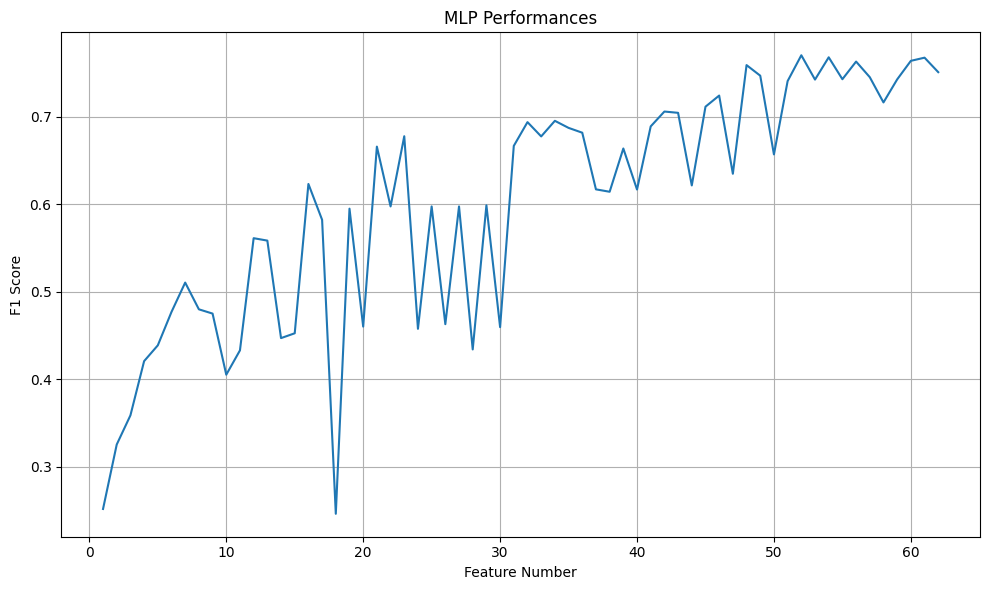

In [119]:
# Training on different feature combinations to find optimal feature number for MLP
tvt_scores = []

for features in tqdm(tvt_subsets.keys()):
    model = MLPClassifier(hidden_layer_sizes=(7,), solver='lbfgs', random_state=SEED)
    model.fit(tvt_subsets[features], y_train)
    n_features = int(features[9-len(features):])  # Get number of features of current models
    tvt_scores.append(validation_stats([model], 
                                       X_val.T[pca_ranks_tvt[:n_features]].T, 
                                       y_val))
    
tvt_scores = np.squeeze(np.array(tvt_scores).T)
best_feat = np.argmax(tvt_scores)+1
print(f"Best feature number: {best_feat} | F1 score: {tvt_scores[best_feat-1]:.3f}")

feat_n = [i for i in range(1, len(tvt_scores)+1)]
plt.figure(figsize=(10, 6))
plt.plot(feat_n, tvt_scores)
plt.xlabel("Feature Number")
plt.ylabel("F1 Score")
plt.title("MLP Performances")
plt.grid(True)
plt.tight_layout()
plt.show()

#### Ex. 3.1.3.

In [120]:
best_solver, best_shape_all, best_score = None, None, 0

In [121]:
# Generate 1 hidden layer shapes and test them
one_hidden_layer = [(i*10,) for i in range(LOWER_LIMIT, UPPER_LIMIT+1)]
tvt_scores = []

if os.path.isfile(f"MLPscores_{LOWER_LIMIT}_{UPPER_LIMIT}_lbfgs.csv"):
    # Read the MLP shape scores from a csv if the same LOWER_LIMIT and UPPER_LIMIT were used
    df = pd.read_csv(f"MLPscores_{LOWER_LIMIT}_{UPPER_LIMIT}_lbfgs.csv")
    tvt_scores = df.to_numpy()
else:
    for shape in tqdm(one_hidden_layer):
        model = MLPClassifier(hidden_layer_sizes=shape, solver='lbfgs', random_state=SEED)
        model.fit(tvt_subsets[f"Features {best_feat}"], y_train)
        tvt_scores.append(np.array(validation_stats([model], 
                                                    X_val.T[pca_ranks_tvt[:best_feat]].T, 
                                                    y_val)[0]))

tvt_scores1 = np.array(tvt_scores if len(np.array(tvt_scores).shape) == 1 else tvt_scores[0])
best_shape1 = np.argmax(tvt_scores1)
print(f"Best one hidden layer shape: {one_hidden_layer[best_shape1]} | F1 score: {tvt_scores1[best_shape1]:.3f}")

Best one hidden layer shape: (50,) | F1 score: 0.784


Best two hidden layer shape: (170, 200) | F1 score: 0.787


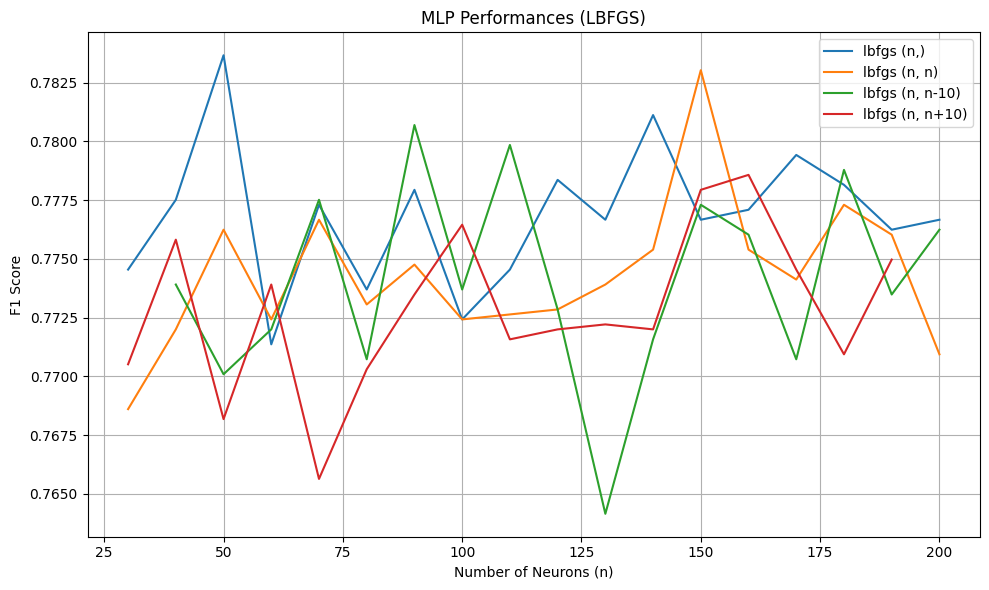

In [122]:
# Generate 2 hidden layers shapes and test them
two_hidden_layers = [[(i*10, j*10) for j in range(LOWER_LIMIT, UPPER_LIMIT+1)] for i in range(LOWER_LIMIT, UPPER_LIMIT+1)]

if not os.path.isfile(f"MLPscores_{LOWER_LIMIT}_{UPPER_LIMIT}_lbfgs.csv"):
    tvt_scores = [tvt_scores]
    for layer1 in tqdm(two_hidden_layers):  # Each list of two_hidden_layers has a fixed amount of layer 1 neurons
        scores = []
        for shape in layer1:
            model = MLPClassifier(hidden_layer_sizes=shape, solver='lbfgs', random_state=SEED)
            model.fit(tvt_subsets[f"Features {best_feat}"], y_train)
            scores.append(validation_stats([model], 
                                           X_val.T[pca_ranks_tvt[:best_feat]].T, 
                                           y_val)[0])
        tvt_scores.append(scores)
    
    # Save MLP f1 scores to a csv file
    df = pd.DataFrame(data=tvt_scores)
    df.to_csv(f"MLPscores_{LOWER_LIMIT}_{UPPER_LIMIT}_lbfgs.csv", index=False)

tvt_scores = np.array(tvt_scores)
best_shape1 = np.argmax(np.max(tvt_scores, axis=1))  # Get the best score by first layer's size
best_shape2 = np.argmax(tvt_scores[best_shape1])  # Get the best score according to the best first layer
best_shape_lbfgs = two_hidden_layers[best_shape1-1][best_shape2] if best_shape1 > 0 else one_hidden_layer[best_shape1]
print(f"Best two hidden layer shape: {best_shape_lbfgs} | F1 score: {tvt_scores[best_shape1][best_shape2]:.3f}")

neuron_n = [i*10 for i in range(LOWER_LIMIT, UPPER_LIMIT+1)]
plot_data = np.array([tvt_scores[i][i-1] for i in range(1, len(tvt_scores))])
plot_data1 = np.array([tvt_scores[i][i-2] for i in range(2, len(tvt_scores))])
plot_data2 = np.array([tvt_scores[i][i] for i in range(1, len(tvt_scores)-1)])
plt.figure(figsize=(10, 6))
plt.plot(neuron_n, tvt_scores[0], label="lbfgs (n,)")
plt.plot(neuron_n, plot_data, label="lbfgs (n, n)")
plt.plot(neuron_n[1:], plot_data1, label="lbfgs (n, n-10)")
plt.plot(neuron_n[:-1], plot_data2, label="lbfgs (n, n+10)")
#for i in range(1, len(tvt_scores)):
#    plt.plot(neuron_n, tvt_scores[i], label=f"lbfgs ({two_hidden_layers[i-1][0][0]}, n)")
plt.xlabel("Number of Neurons (n)")
plt.ylabel("F1 Score")
plt.title("MLP Performances (LBFGS)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [123]:
# Generate 1 hidden layer shapes and test them
one_hidden_layer = [(i*10,) for i in range(LOWER_LIMIT, UPPER_LIMIT+1)]
best_sgd_score = 0
tvt_scores = []

if os.path.isfile(f"MLPscores_{LOWER_LIMIT}_{UPPER_LIMIT}_sgd.csv"):
    # Read the MLP shape scores from a csv if the same LOWER_LIMIT and UPPER_LIMIT were used
    df = pd.read_csv(f"MLPscores_{LOWER_LIMIT}_{UPPER_LIMIT}_sgd.csv")
    tvt_scores = df.to_numpy()
else:
    for shape in tqdm(one_hidden_layer):
        model = MLPClassifier(hidden_layer_sizes=shape, solver='sgd', random_state=SEED)
        model.fit(tvt_subsets[f"Features {best_feat}"], y_train)
        tvt_scores.append(np.array(validation_stats([model], 
                                                    X_val.T[pca_ranks_tvt[:best_feat]].T, 
                                                    y_val)[0]))

tvt_scores1 = np.array(tvt_scores if len(np.array(tvt_scores).shape) == 1 else tvt_scores[0])
best_shape1 = np.argmax(tvt_scores1)
print(f"Best one hidden layer shape: {one_hidden_layer[best_shape1]} | F1 score: {tvt_scores1[best_shape1]:.3f}")

Best one hidden layer shape: (130,) | F1 score: 0.729


Best two hidden layer shape: (150, 110) | F1 score: 0.758


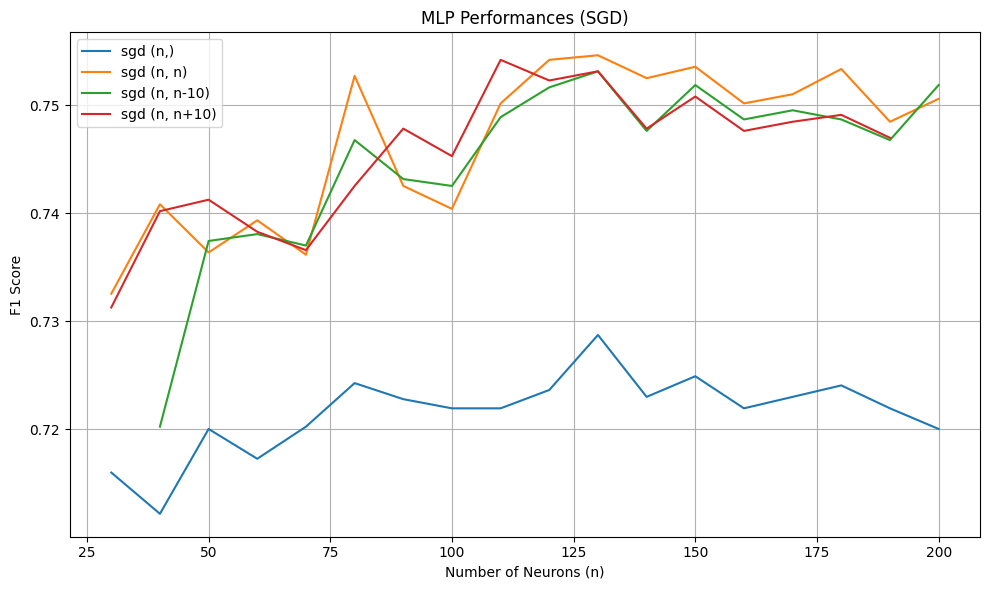

In [124]:
# Generate 2 hidden layers shapes and test them
two_hidden_layers = [[(i*10, j*10) for j in range(LOWER_LIMIT, UPPER_LIMIT+1)] for i in range(LOWER_LIMIT, UPPER_LIMIT+1)]

if not os.path.isfile(f"MLPscores_{LOWER_LIMIT}_{UPPER_LIMIT}_sgd.csv"):
    tvt_scores = [tvt_scores]
    for layer1 in tqdm(two_hidden_layers):  # Each list of two_hidden_layers has a fixed amount of layer 1 neurons
        scores = []
        for shape in layer1:
            model = MLPClassifier(hidden_layer_sizes=shape, solver='sgd', random_state=SEED)
            model.fit(tvt_subsets[f"Features {best_feat}"], y_train)
            scores.append(validation_stats([model], 
                                           X_val.T[pca_ranks_tvt[:best_feat]].T, 
                                           y_val)[0])
        tvt_scores.append(scores)
    
    # Save MLP f1 scores to a csv file
    df = pd.DataFrame(data=tvt_scores)
    df.to_csv(f"MLPscores_{LOWER_LIMIT}_{UPPER_LIMIT}_sgd.csv", index=False)

tvt_scores = np.array(tvt_scores)
best_shape1 = np.argmax(np.max(tvt_scores, axis=1))  # Get the best score by first layer's size
best_shape2 = np.argmax(tvt_scores[best_shape1])  # Get the best score according to the best first layer
best_shape_sgd = two_hidden_layers[best_shape1-1][best_shape2] if best_shape1 > 0 else one_hidden_layer[best_shape1]
if tvt_scores[best_shape1][best_shape2] > best_score:
    best_solver, best_shape_all, best_score = 'sgd', best_shape_sgd, tvt_scores[best_shape1][best_shape2]
print(f"Best two hidden layer shape: {best_shape_sgd} | F1 score: {tvt_scores[best_shape1][best_shape2]:.3f}")

neuron_n = [i*10 for i in range(LOWER_LIMIT, UPPER_LIMIT+1)]
plot_data = np.array([tvt_scores[i][i-1] for i in range(1, len(tvt_scores))])
plot_data1 = np.array([tvt_scores[i][i-2] for i in range(2, len(tvt_scores))])
plot_data2 = np.array([tvt_scores[i][i] for i in range(1, len(tvt_scores)-1)])
plt.figure(figsize=(10, 6))
plt.plot(neuron_n, tvt_scores[0], label="sgd (n,)")
plt.plot(neuron_n, plot_data, label="sgd (n, n)")
plt.plot(neuron_n[1:], plot_data1, label="sgd (n, n-10)")
plt.plot(neuron_n[:-1], plot_data2, label="sgd (n, n+10)")
#for i in range(1, len(tvt_scores)):
#    plt.plot(neuron_n, tvt_scores[i], label=f"sgd ({two_hidden_layers[i-1][0][0]}, n)")
plt.xlabel("Number of Neurons (n)")
plt.ylabel("F1 Score")
plt.title("MLP Performances (SGD)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [125]:
# Generate 1 hidden layer shapes and test them
one_hidden_layer = [(i*10,) for i in range(LOWER_LIMIT, UPPER_LIMIT+1)]
tvt_scores = []

if os.path.isfile(f"MLPscores_{LOWER_LIMIT}_{UPPER_LIMIT}_adam.csv"):
    # Read the MLP shape scores from a csv if the same LOWER_LIMIT and UPPER_LIMIT were used
    df = pd.read_csv(f"MLPscores_{LOWER_LIMIT}_{UPPER_LIMIT}_adam.csv")
    tvt_scores = df.to_numpy()
else:
    for shape in tqdm(one_hidden_layer):
        model = MLPClassifier(hidden_layer_sizes=shape, solver='adam', random_state=SEED)
        model.fit(tvt_subsets[f"Features {best_feat}"], y_train)
        tvt_scores.append(np.array(validation_stats([model], 
                                                    X_val.T[pca_ranks_tvt[:best_feat]].T, 
                                                    y_val)[0]))

tvt_scores1 = np.array(tvt_scores if len(np.array(tvt_scores).shape) == 1 else tvt_scores[0])
best_shape1 = np.argmax(tvt_scores1)
print(f"Best one hidden layer shape: {one_hidden_layer[best_shape1]} | F1 score: {tvt_scores1[best_shape1]:.3f}")

Best one hidden layer shape: (120,) | F1 score: 0.794


Best two hidden layer shape: (150, 180) | F1 score: 0.807


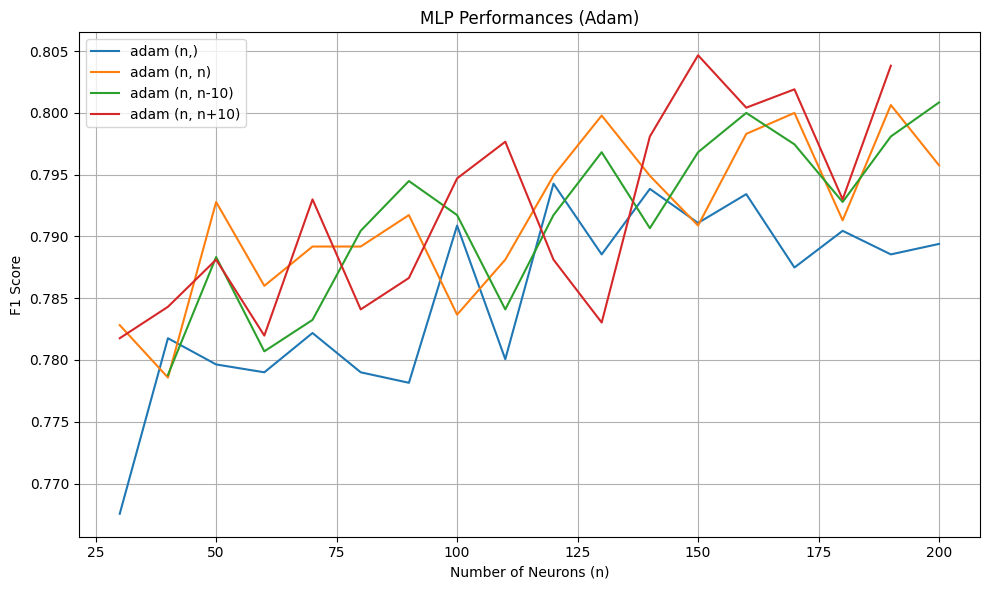

In [126]:
# Generate 2 hidden layers shapes and test them
two_hidden_layers = [[(i*10, j*10) for j in range(LOWER_LIMIT, UPPER_LIMIT+1)] for i in range(LOWER_LIMIT, UPPER_LIMIT+1)]

if not os.path.isfile(f"MLPscores_{LOWER_LIMIT}_{UPPER_LIMIT}_adam.csv"):
    tvt_scores = [tvt_scores]
    for layer1 in tqdm(two_hidden_layers):  # Each list of two_hidden_layers has a fixed amount of layer 1 neurons
        scores = []
        for shape in layer1:
            model = MLPClassifier(hidden_layer_sizes=shape, solver='adam', random_state=SEED)
            model.fit(tvt_subsets[f"Features {best_feat}"], y_train)
            scores.append(validation_stats([model], 
                                           X_val.T[pca_ranks_tvt[:best_feat]].T, 
                                           y_val)[0])
        tvt_scores.append(scores)
    
    # Save MLP f1 scores to a csv file
    df = pd.DataFrame(data=tvt_scores)
    df.to_csv(f"MLPscores_{LOWER_LIMIT}_{UPPER_LIMIT}_adam.csv", index=False)

tvt_scores = np.array(tvt_scores)
best_shape1 = np.argmax(np.max(tvt_scores, axis=1))  # Get the best score by first layer's size
best_shape2 = np.argmax(tvt_scores[best_shape1])  # Get the best score according to the best first layer
best_shape_adam = two_hidden_layers[best_shape1-1][best_shape2] if best_shape1 > 0 else one_hidden_layer[best_shape1]
if tvt_scores[best_shape1][best_shape2] > best_score:
    best_solver, best_shape_all, best_score = 'adam', best_shape_adam, tvt_scores[best_shape1][best_shape2]
print(f"Best two hidden layer shape: {best_shape_adam} | F1 score: {tvt_scores[best_shape1][best_shape2]:.3f}")

neuron_n = [i*10 for i in range(LOWER_LIMIT, UPPER_LIMIT+1)]
plot_data = np.array([tvt_scores[i][i-1] for i in range(1, len(tvt_scores))])
plot_data1 = np.array([tvt_scores[i][i-2] for i in range(2, len(tvt_scores))])
plot_data2 = np.array([tvt_scores[i][i] for i in range(1, len(tvt_scores)-1)])
plt.figure(figsize=(10, 6))
plt.plot(neuron_n, tvt_scores[0], label="adam (n,)")
plt.plot(neuron_n, plot_data, label="adam (n, n)")
plt.plot(neuron_n[1:], plot_data1, label="adam (n, n-10)")
plt.plot(neuron_n[:-1], plot_data2, label="adam (n, n+10)")
#for i in range(1, len(tvt_scores)):
#    plt.plot(neuron_n, tvt_scores[i], label=f"adam ({two_hidden_layers[i-1][0][0]}, n)")
plt.xlabel("Number of Neurons (n)")
plt.ylabel("F1 Score")
plt.title("MLP Performances (Adam)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [127]:
# Different parameters with the best shapes from all solvers for adam solver
shapes = [best_shape_lbfgs, best_shape_sgd, best_shape_adam]
activations = ['relu', 'identity', 'logistic', 'tanh']  # Default value = 'relu'
learning_rate_init = [0.01, 0.001, 0.0001]  # Default value = 0.001
epochs = [100, 200, 250, 500, 750, 1000]  # Default value = 200
best_activation_all, best_lr_all, best_epoch_all = 'relu', 0.001, 200

for best_shape in shapes:
    tvt_scores = []
    if os.path.isfile(f"MLPscores_{LOWER_LIMIT}_{UPPER_LIMIT}_adam_{best_shape}.csv"):
        # Read the MLP shape scores from a csv if the same LOWER_LIMIT, UPPER_LIMIT, best solver and best shape were used
        df = pd.read_csv(f"MLPscores_{LOWER_LIMIT}_{UPPER_LIMIT}_adam_{best_shape}.csv")
        tvt_scores = df.to_numpy()
    else:
        for activation in activations:
            for lr in learning_rate_init:
                for epoch in tqdm(epochs):
                    model = MLPClassifier(hidden_layer_sizes=best_shape, 
                                          solver='adam', 
                                          activation=activation,
                                          learning_rate_init=lr,
                                          max_iter=epoch,
                                          batch_size='auto',  # Auto was found to be the best one
                                          random_state=SEED)
                    model.fit(tvt_subsets[f"Features {best_feat}"], y_train)
                    tvt_scores.append(validation_stats([model],
                                                       X_val.T[pca_ranks_tvt[:best_feat]].T, 
                                                       y_val)[0])
                    
        # Save MLP f1 scores to a csv file
        df = pd.DataFrame(data=tvt_scores)
        df.to_csv(f"MLPscores_{LOWER_LIMIT}_{UPPER_LIMIT}_{best_solver}_{best_shape}.csv", index=False)

    tvt_scores = np.array(tvt_scores).flatten()
    best_combo = np.argmax(tvt_scores)
    best_activation = best_combo // (len(epochs)*len(learning_rate_init))
    best_lr = (best_combo % (len(epochs)*len(learning_rate_init))) // len(epochs)
    best_epoch = best_combo % len(epochs)
    if tvt_scores[best_combo] > best_score:
        best_score = tvt_scores[best_combo]
        best_shape_all = best_shape
        best_activation_all = activations[best_activation]
        best_lr_all = learning_rate_init[best_lr]
        best_epoch_all = epochs[best_epoch]
    print(f"Solver: adam | Shape: {best_shape} | Best activation: {activations[best_activation]} | Best learning rate: {learning_rate_init[best_lr]} | \
Best epoch number: {epochs[best_epoch]} | F1 score: {tvt_scores[best_combo]:.3f}")
    
print(f"\nBest solver: {best_solver} | Best shape: {best_shape_all} | Best activation: {best_activation_all} | Best learning rate: {best_lr_all}\
 | Best epoch number: {best_epoch_all} | F1 score: {best_score:.3f}")

Solver: adam | Shape: (170, 200) | Best activation: tanh | Best learning rate: 0.001 | Best epoch number: 250 | F1 score: 0.802
Solver: adam | Shape: (150, 110) | Best activation: tanh | Best learning rate: 0.001 | Best epoch number: 200 | F1 score: 0.803
Solver: adam | Shape: (150, 180) | Best activation: relu | Best learning rate: 0.001 | Best epoch number: 200 | F1 score: 0.807

Best solver: adam | Best shape: (150, 180) | Best activation: relu | Best learning rate: 0.001 | Best epoch number: 200 | F1 score: 0.807


### Ex. 3.2.

In [128]:
mlp_model = MLPClassifier(hidden_layer_sizes=best_shape_all, 
                      solver=best_solver, 
                      activation=best_activation_all,
                      learning_rate_init=best_lr_all,
                      max_iter=best_epoch_all,
                      batch_size='auto',  # Auto was found to be the best one
                      random_state=SEED)
mlp_model

MLPClassifier(hidden_layer_sizes=(150, 180), random_state=42)

In [129]:
# Training data = training + validation data
X_train_val = np.concat((X_train, X_val)).T[pca_ranks_tvt[:best_feat]].T
y_train_val = np.concat((y_train, y_val))

# Re-normalize data to fit the new scaling
scaler_combined = MinMaxScaler()
scaler_combined.fit(X_train_val)
X_train_val_scaled = scaler_combined.transform(X_train_val)
X_test_scaled = scaler_combined.transform(X_test.T[pca_ranks_tvt[:best_feat]].T)

X_train_val.shape, y_train_val.shape

((11000, 52), (11000,))

#### Ex. 3.2.1.

Precision score: 0.804
Recall score: 0.804
F1 score: 0.804


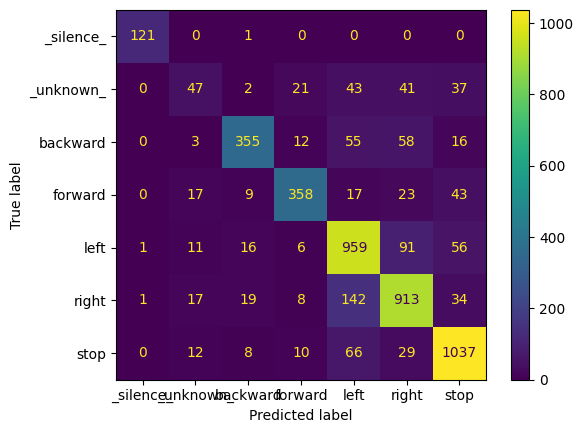

In [130]:
# Classification with the best model on test set
mlp_model.fit(X_train_val_scaled, y_train_val)
preds = mlp_model.predict(X_test_scaled)
confmat, precision, recall, f1 = evaluation_metrics(y_test, preds)

print(f"Precision score: {precision:.3f}\nRecall score: {recall:.3f}\nF1 score: {f1:.3f}")
ConfusionMatrixDisplay.from_predictions(y_test, preds);

In [131]:
# Compute the scaler for wheelchair game (to scale the train_val set without previous normalization)
X_train_val_toscale = np.concat((X_train_toscale, X_val_toscale)).T[pca_ranks_tvt[:best_feat]].T
scaler_ex5 = MinMaxScaler()
scaler_ex5.fit(X_train_val_toscale)
X_train_val_toscale1 = scaler_ex5.transform(X_train_val_toscale)
X_train_val_toscale1, X_train_val_toscale1.shape

(array([[0.27783824, 0.66524828, 0.86032327, ..., 0.0229443 , 0.03188496,
         0.04132624],
        [0.41529439, 0.46374801, 0.64612659, ..., 0.39936079, 0.38937977,
         0.2434221 ],
        [0.44785398, 0.46420285, 0.39988244, ..., 0.34381996, 0.48108496,
         0.22046129],
        ...,
        [0.47903293, 0.39077639, 0.59862518, ..., 0.11292056, 0.1211485 ,
         0.23985445],
        [0.58716808, 0.37832493, 0.73727084, ..., 0.2043182 , 0.34529052,
         0.07219495],
        [0.47873012, 0.61528241, 0.40195693, ..., 0.35247679, 0.32394465,
         0.2382414 ]]),
 (11000, 52))

In [132]:
# Save the scaler, model and PCA ranking for wheelchair game
joblib.dump(scaler_ex5, 'scaler.pkl')  # Scaler for train_val normalized
joblib.dump(mlp_model, 'model.pkl')
joblib.dump(pca_ranks_tvt[:best_feat], 'feature_ranks.pkl')

['feature_ranks.pkl']

#### Ex. 3.2.2.

Precision score: 0.900
Recall score: 0.900
F1 score: 0.900


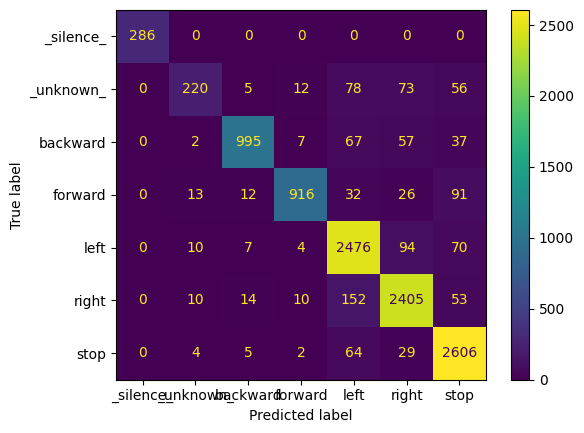

In [140]:
# Classification with the best model on training set
mlp_model.fit(X_train_val_scaled, y_train_val)
preds = mlp_model.predict(X_train_val_scaled)
confmat, precision, recall, f1 = evaluation_metrics(y_train_val, preds)

print(f"Precision score: {precision:.3f}\nRecall score: {recall:.3f}\nF1 score: {f1:.3f}")
ConfusionMatrixDisplay.from_predictions(y_train_val, preds);

#### Ex. 3.2.3. Overfitting assessment

Although the performance on the training set is higher than the test set, which might suggest overfitting, there isn't a big disparity between the two. In an ideal scenario, the training performance should be reflected on the test set performance. But, in the case of MLPs, there's a tendency for the model's performance on the training set to be better than the one on the test set, mostly due to optimizing with respect to the training loss and because of the complexity and stochastic nature of the training. In conclusion, although big discrepancies between training scores/losses and test scores/losses might indicate the presence of overfitting in MLPs, here there isn't that big of a difference, suggesting the model can't better generalize the test set and that it might be slightly overfitting.

### Ex. 3.3. kNN vs MLP

Both kNN and MLP are vastly different machine learning model architectures and so, before directly comparing their results, let's see what each one does.

**kNN** relies on a distance based approach to determine the classes the test samples belong to by computing the distance (Manhattan, Euclidean) of each test instance to every training instance, followed by finding out the majority class of the k nearest training instances, which is then used to classify the test instance in question. 

On the other hand, **MLP** attempts to find complex relationships between the data by applying consecutive linear and non linear (ReLU, sigmoid, tanh) transformations to it. MLPs typically use a loss function (Mean Squared Error, Cross Entropy) to compute how "wrong" a prediction is and an optimizer (SGD, Adam, LBFGS) to backpropagate the loss and adjust the model's weights and biases. MLPs also use a stochastic approach to better explore the optimization space and avoid suscepibility to local minima.

Let's compare the results now:

1. **Performance** - Being a simpler model, it was expected that kNN would perform worse than the MLP, with a F1 score of 0.777 compared to the MLP's 0.804, a 0.027 difference. According to the confusion matrices, the MLP had a better prediction accuracy than the kNN model, with the only exception being the 'right' class, where kNN had more prediction accuracy than the MLP. Some interesting characteristics about the performances iare that neither model was able to reliably predict the 'unknown' class and that both models had most confusion predicting 'right', 'left' and 'stop'.

2. **Generalization** - We can see the generalization capacity when it comes to prediction performance on the training set. From this metric we can conclude that MLP has a better generalization capacity than kNN due to former achieving 0.900 F1 score compared to the latter's 1.000 score on the training set. This demonstrates that kNN heavily overfits the training set, while MLP might only be slightly overfitting this same set, thus leading to the conclusing that the MLP has better generalization power than kNN.

3. **Computational Complexity** - During the parameter tuning phase, it was observed that executions related to model training and performance assessment took up to 10x more to execute on the MLP when compared to kNN. This shows that, although the MLP is capable of capturing more complex relationships in data and better generalizing it, it's also way more computationally expensive to train and fine tune compared to kNN, as many more linear and non-linear computations are being performed in contrast to distance calculations over all data points.

## Ex. 4

In [134]:
class Layer:
    ''' Defines a base class for a layer of the neural network (inputs and outputs) and its operations (forward and backward propagations) '''
    def __init__(self):
        ''' Contains the layer's inputs and outputs (useful for propagation) '''
        # Weights and biases are initialized stochastically (randomly)
        self.input = None  # Shape: (input, output)
        self.output = None  # Shape: (1, output)
    
    def forward(self, input):
        ''' Base method for forward propagation (later implemented in FCLayer) '''
        raise NotImplementedError
    
    def backward(self, output_loss, lr):
        ''' Base method for backward propagation (later implemented in FCLayer) '''
        raise NotImplementedError

In [135]:
class FCLayer(Layer):
    ''' Expands upon the Layer class, by adding the weights and biases to the layer and implementing the forward and backward propagation methods. 
        This class realizes the Fully Connected (FC) Layer concept. '''
    def __init__(self, input_size, output_size):
        ''' Defines the weights and biases according to layer shape (weight matrix) '''
        # Weights and biases are initialized stochastically (randomly)
        self.weights = np.random.rand(input_size, output_size) - 0.5  # Shape: (input, output)
        self.bias = np.random.rand(1, output_size) - 0.5  # Shape: (1, output)
        
    def forward(self, input):
        ''' Performs a forward propagation on the layer (linear transformation) '''
        self.input = input  # Save the input data for backpropagation
        self.output = np.dot(self.input, self.weights) + self.bias  # Y = W*X + B
        return self.output
    
    def backward(self, output_loss, lr):
        ''' Computes the gradient (dL/dX) for a given loss, output and learning rate (lr*dL/dY).
            Starting from the network output, where a loss function computes the output loss:
            1. A layer receives the output loss (dL/dY)
            2. To adjust the parameters, the layer computes the loss' derivative w.r.t. to them (dL/dW, dL/dB) 
            2.1. Since it's fully connected, the layer computes the loss of every output w.r.t. every weight:
                    dL/dwij = dL/dy1 * dy1/dwij + dL/dy2 * dy2/dwij + ... + dL/dyj * dyj/dwij = dL/dyj*xi
                 We can generalize this process for a whole weight matrix as the following:
                    dL/dW = [x1 ... xi] x [dL/dy1 ... dL/dyj] = X.T x dL/dY (X.T to get a matrix of shape (i, j))
            2.2. For the bias, we have:
                    dL/dbj = dL/dy1 * dy1/dbj + dL/dy2 * dy2/dbj + ... + dL/dyj * dyj/dbj = dL/dyj
                 If we generalize the above for the bias matrix we get:
                    dL/dB = [dL/dy1 dL/dy2 ... dL/dyj] = dL/dY
            3. With dL/dW and dL/dB computed, we can now compute the input of the current layer (dL/dY of the previous):
                    dL/dxi = dL/dy1 * dy1/dxi + ... + dL/dyj * dyj/dxi = dL/dy1 * wi1 + ... + dL/dyj * wij
               We can then generalize the above for the input matrix X:
                    dL/dX = [(dL/dy1 * w11 + ... + dL/dyj * w1j) ... (dL/dy1 * wi1 + ... + dL/dyj * wij])] = dL/dY x W.T
            4. Repeat until all layers are covered
            With this, we just defined the backpropagation algorithm. 
            Note: In the formulas above, x denotes dot product and * denotes element-wise multiplication. '''
        input_loss = np.dot(output_loss, self.weights.T)  # dL/dW = dL/dY * W.T
        weights_loss = np.dot(self.input.T, output_loss)  # dL/dW = X.T * dL/dY
        
        # Update weights and biases according to learning rate (lr)
        self.weights -= lr * weights_loss  # lr * dL/dW
        self.bias -=  lr * output_loss  # lr * dL/dY
        return input_loss  # Used by the layer previous to this one in forward propagation

In [136]:
class ActivationLayer(Layer):
    ''' Expands upon the Layer class, by allowing the introduction of non-linear functions to the output of the layers.
        This class realizes the Activation Function concept. '''
    def __init__(self, activation, activation_prime):
        ''' Takes in an activation function and its derivative (for backpropagation) '''
        self.activation = activation  # Normal activation function (f)
        self.activation_prime = activation_prime  # Derivative of the above activation function (f')
        
    def forward(self, input_data):
        ''' Defines a forward propagation on a layer's output (non-linear transformation) '''
        self.input = input_data  # Save the input data for backpropagation
        self.output = np.vectorize(self.activation)(self.input)  # Apply activation function (Y = f(X))
        return self.output
    
    def backward(self, output_loss, lr):
        ''' Applies the backward propagation on the activation function.
            The objective here is, just like the FCLayer, to compute the loss w.r.t. the input (dL/dX). We have:
                dL/dX = [dL/dx1 ... dL/xi] =
                      = [(dL/dy1 * dy1/dx1) ... (dL/dyi * dyi/dxi)] =
                      = [(dL/dy1 * f'(x1)) ... (dL/dyi * f'(xi))] =
                      = [dL/dy1 ... dL/dyi] * [f'(x1) ... f'(xi)] =
                      = dL/dY * f'(X)
            This is a simple computation since dL/dY is the loss of the output of the current layer and f' the activation function's derivative.
            Notice that learning rate isn't applied here because the activation function doesn't have learnable parameters (weights, biases).
            Note: Just like in the FCLayer, * represent element-wise multiplication. ''' 
        return np.vectorize(self.activation_prime)(self.input) * output_loss

In [137]:
class NeuralNetwork:
    ''' Combines the layer classes to build and manage a neural network.
        This class realizes the Multilayer Perceptron (MLP) concept. '''
    def __init__(self):
        ''' Stores the layers in the network and the loss function (and its derivative) used '''
        self.layers = []  # Contains the layers
        self.loss = None  # Loss function (L)
        self.loss_prime = None  # Derivative of the loss function (L')
        
    def add(self, layer):
        ''' Adds a layer to the stack '''
        self.layers.append(layer)
        
    def set_loss(self, loss, loss_prime):
        ''' Method to set the loss functions to be used in the training loop '''
        self.loss = loss
        self.loss_prime = loss_prime
    
    def predict(self, input_data):
        ''' Used to make predictions through forward propagation.
            Returns a list of predictions, according to the number of input samples. '''
        result = []
        
        for sample in input_data:
            output = sample
            for layer in self.layers:  # Go through each layer individually
                output = layer.forward(output)  # Iteratively update the output
            result.append(output)
        
        return result
    
    def fit(self, X_train, y_train, epochs, lr):
        ''' Takes in array of training samples and another for the labels, a number of epochs and a learning rate.
            Defines the training (fitting) process of the MLP. '''
        for i in range(epochs):
            total_loss = 0  # For printing
            for sample, label in zip(X_train, y_train):
                output = sample
                for layer in self.layers:  # Forward propagation
                    output = layer.forward(output)
                    
                total_loss += self.loss(label, output)
                
                loss = self.loss_prime(label, output)
                for layer in reversed(self.layers):  # Backward propagation
                    loss = layer.backward(loss, lr)
                
            total_loss /= len(X_train)
            print(f"Epoch: {i+1} | Loss: {total_loss:.4f}")

In [138]:
# Activation and loss functions for the custom neural network
def relu(x):
    ''' ReLU (Rectified Linear Unit) activation function '''
    return max(0, x)

def relu_prime(x):
    ''' Derivative of the ReLU activation function '''
    return 0 if x < 0 else 1

def MSE(y_true, pred):
    ''' MSE (Mean Squared Error) loss function '''
    return np.mean(np.power(y_true-pred, 2))

def MSE_prime(y_true, pred):
    ''' Derivative of the MSE loss function'''
    return 2*(pred-y_true)/y_true.size

In [139]:
# One hot encoding for labels to compute output's loss
encoder = OneHotEncoder(sparse_output=False)
y_train_custom = encoder.fit_transform(y_train.reshape(-1, 1))

# Defines the network architecture
nn = NeuralNetwork()
nn.add(FCLayer(X_train_val_scaled.shape[1], best_shape_all[0]))
nn.add(ActivationLayer(relu, relu_prime))
nn.add(FCLayer(best_shape_all[0], best_shape_all[1]))
nn.add(ActivationLayer(relu, relu_prime))
nn.add(FCLayer(best_shape_all[1], len(labels)))
nn.add(ActivationLayer(relu, relu_prime))

# Set the loss function
nn.set_loss(MSE, MSE_prime)

# Train
# Note: There needs to be an extra dim for transpositions of 1-dim arrays to work as intended
nn.fit(np.expand_dims(X_train_val_scaled, axis=1), np.expand_dims(y_train_custom, axis=1), 3, best_lr_all)

Epoch: 1 | Loss: 0.0892
Epoch: 2 | Loss: 0.0818
Epoch: 3 | Loss: 0.0817
